<a href="https://colab.research.google.com/github/Dani-Mol/InteligenciaArtificial/blob/main/09_29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clase 09-29


## Sección 6: Red Neuronal Multicapa para el Conjunto de Datos

A diferencia del Perceptrón Simple que solo puede trazar fronteras lineales, una **Red Neuronal Multicapa (MLP)** puede resolver problemas no lineales como el conjunto de datos de círculos concéntricos.

Siguiendo las especificaciones, construiremos un modelo con:
*   **Dos capas ocultas**.
*   Función de activación **Softmax** (aplicada en la capa de salida para obtener probabilidades por clase). En las capas ocultas usaremos ReLU, ya que Softmax en capas ocultas dificulta la convergencia.
*   Función de pérdida de **Error Cuadrático Medio (MSE)**. *Nota: Para usar MSE con Softmax, transformaremos nuestras etiquetas (0 y 1) a formato "One-Hot" (ej. [1, 0] y [0, 1]).*

Primero, generamos el conjunto de datos y lo preparamos:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,)


import torch
import torch.nn as nn
import torch.optim as optim

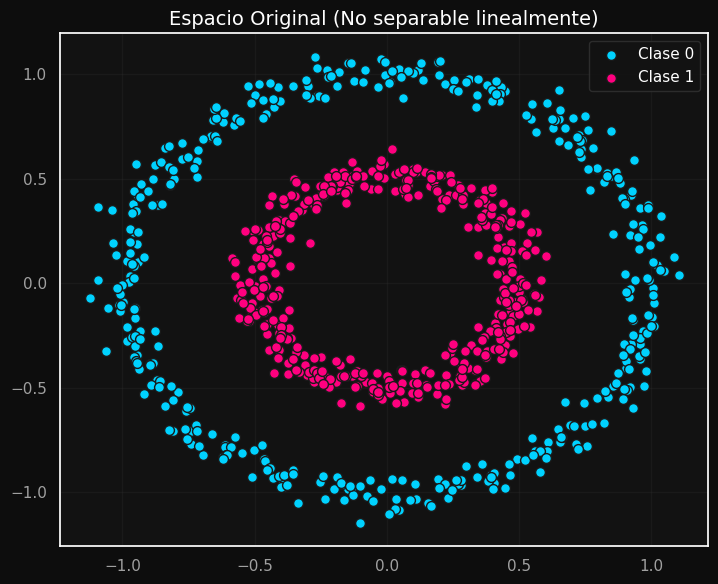

In [ ]:
from sklearn.datasets import make_circles
import torch.nn.functional as F

# Generamos un dataset no lineal
X_data, y_data = make_circles(n_samples=800, noise=0.05, factor=0.5, random_state=42)

sns.set_theme(
    style="darkgrid",
    rc={
        "axes.facecolor": "#121212",
        "figure.facecolor": "#0d0d0d",
        "text.color": "white",
        "axes.labelcolor": "white",
        "xtick.color": "#a0a0a0",
        "ytick.color": "#a0a0a0",
        "grid.color": "#333333",
    },
)

fig = plt.figure(figsize=(14, 6))

# Espacio Original (2D)
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(X_data[y_data==0, 0], X_data[y_data==0, 1], color='#00d2ff', edgecolor='k', s=50, label='Clase 0')
ax1.scatter(X_data[y_data==1, 0], X_data[y_data==1, 1], color='#ff007f', edgecolor='k', s=50, label='Clase 1')
ax1.set_title("Espacio Original (No separable linealmente)", fontsize=14)
ax1.legend(facecolor='#121212', edgecolor='#333333', labelcolor='white')


plt.tight_layout()
plt.show()


In [ ]:
# División train/test
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_data, y_data, test_size=0.3, random_state=42, stratify=y_data
)

# Estandarización de los nuevos datos
scaler = StandardScaler()
X_c_train_N = scaler.fit_transform(X_c_train)
X_c_test_N = scaler.transform(X_c_test)

# Conversión a tensores de PyTorch
X_c_train_T = torch.tensor(X_c_train_N, dtype=torch.float32)
X_c_test_T = torch.tensor(X_c_test_N, dtype=torch.float32)

# Convertimos las etiquetas a tensores Long (enteros)
y_c_train_T = torch.tensor(y_c_train, dtype=torch.long)
y_c_test_T = torch.tensor(y_c_test, dtype=torch.long)

# Aplicamos One-Hot Encoding necesario para combinar Softmax + MSELoss
# Transforma las etiquetas 0 y 1 a tensores [1.0, 0.0] y [0.0, 1.0]
y_c_train_oh = F.one_hot(y_c_train_T, num_classes=2).float()
y_c_test_oh = F.one_hot(y_c_test_T, num_classes=2).float()

### Definición y Entrenamiento de la Red Multicapa

Construiremos un modelo heredado de `nn.Module` compuesto por:
1.  **Capa Oculta 1:** Proyección lineal de 2 características a 16 neuronas + Activación ReLU.
2.  **Capa Oculta 2:** Proyección lineal de 16 neuronas a 16 neuronas + Activación ReLU.
3.  **Capa de Salida:** Proyección a 2 neuronas + Función **Softmax** para obtener salidas distribuidas entre 0 y 1.

In [ ]:
# DEFINICIÓN DEL MODELO MULTICAPA
class RedMulticapaCircles(nn.Module):
    def __init__(self):
        super(RedMulticapaCircles, self).__init__()
        # Exactamente dos capas ocultas
        self.capa_oculta1 = nn.Linear(2, 16)
        self.activacion1 = nn.ReLU()

        self.capa_oculta2 = nn.Linear(16, 16)
        self.activacion2 = nn.ReLU()

        # Salida hacia 2 neuronas
        self.capa_salida = nn.Linear(16, 2)
        # Softmax a través de la dimensión de las características
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.activacion1(self.capa_oculta1(x))
        x = self.activacion2(self.capa_oculta2(x))
        x = self.capa_salida(x)
        return self.softmax(x)

modelo_circ = RedMulticapaCircles()

# Función de pérdida MSE
f_perdida_mse = nn.MSELoss()

# Optimizador Adam
optimizador_circ = optim.Adam(modelo_circ.parameters(), lr=0.01)


# CICLO DE ENTRENAMIENTO
epocas = 100
for epoca in range(epocas):
    optimizador_circ.zero_grad()

    # Forward pass: predicción de probabilidades
    y_pred = modelo_circ(X_c_train_T)

    # Cálculo de pérdida MSE comparando salidas vs etiquetas en One-Hot
    perdida = f_perdida_mse(y_pred, y_c_train_oh)

    # Backward pass y actualización de pesos
    perdida.backward()
    optimizador_circ.step()

    if (epoca + 1) % 5 == 0:
        print(f"Época [{epoca+1}/{epocas}], Pérdida MSE: {perdida.item():.4f}")

Época [5/100], Pérdida MSE: 0.2322
Época [10/100], Pérdida MSE: 0.2008
Época [15/100], Pérdida MSE: 0.1525
Época [20/100], Pérdida MSE: 0.0941
Época [25/100], Pérdida MSE: 0.0449
Época [30/100], Pérdida MSE: 0.0168
Época [35/100], Pérdida MSE: 0.0060
Época [40/100], Pérdida MSE: 0.0024
Época [45/100], Pérdida MSE: 0.0012
Época [50/100], Pérdida MSE: 0.0007
Época [55/100], Pérdida MSE: 0.0004
Época [60/100], Pérdida MSE: 0.0003
Época [65/100], Pérdida MSE: 0.0002
Época [70/100], Pérdida MSE: 0.0002
Época [75/100], Pérdida MSE: 0.0002
Época [80/100], Pérdida MSE: 0.0001
Época [85/100], Pérdida MSE: 0.0001
Época [90/100], Pérdida MSE: 0.0001
Época [95/100], Pérdida MSE: 0.0001
Época [100/100], Pérdida MSE: 0.0001


### Visualización de la Frontera de Decisión

Evaluaremos visualmente cómo las capas ocultas y las activaciones no lineales han permitido al modelo deformar el espacio para atrapar la clase central. Reciclaremos el diccionario de parámetros estéticos configurado previamente en Seaborn.

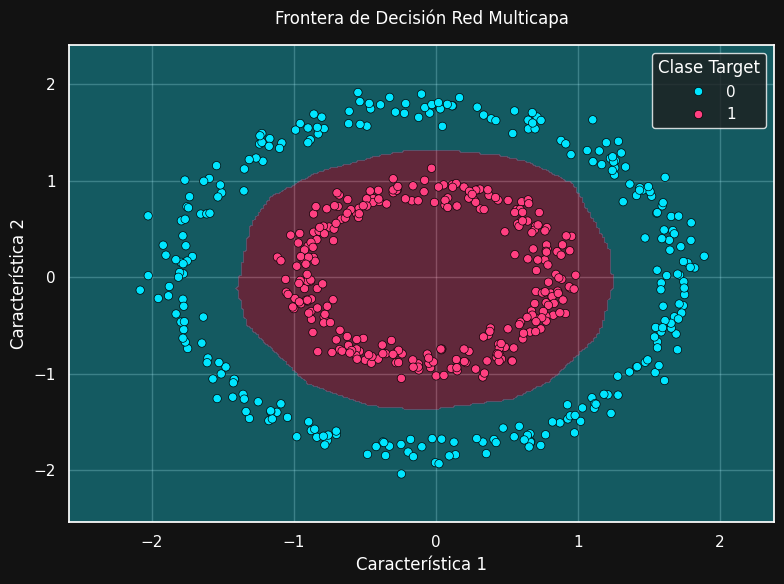

In [ ]:
# GRAFICACIÓN DE FRONTERA DE DECISIÓN
sns.set_theme(
    style="darkgrid",
    palette="bright",
    rc={
        "axes.facecolor": "#1e1e1e",
        "figure.facecolor": "#121212",
        "text.color": "white",
        "axes.labelcolor": "white",
        "xtick.color": "white",
        "ytick.color": "white",
        "grid.color": "#ffffff",
        "grid.alpha": 0.25,
        "axes.grid": True,
    },
)
colores_custom = ["#00E5FF", "#FF4081"]

# Creamos una cuadrícula densa en el espacio 2D
x_min, x_max = X_c_train_N[:, 0].min() - 0.5, X_c_train_N[:, 0].max() + 0.5
y_min, y_max = X_c_train_N[:, 1].min() - 0.5, X_c_train_N[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Transformamos la malla a tensores y realizamos la predicción global
grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

with torch.no_grad():
    preds_grid = modelo_circ(grid_tensor)
    # torch.argmax extrae la clase (0 o 1) con la probabilidad más alta dictada por Softmax
    Z = torch.argmax(preds_grid, dim=1).numpy()

Z = Z.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))

# Dibujamos el contorno de clase
ax.contourf(xx, yy, Z, alpha=0.3, levels=[-0.5, 0.5, 1.5], colors=colores_custom)

# Superponemos las observaciones reales
sns.scatterplot(
    x=X_c_train_N[:, 0],
    y=X_c_train_N[:, 1],
    hue=y_c_train,
    palette=colores_custom,
    edgecolor="black",
    ax=ax
)

ax.set_title("Frontera de Decisión Red Multicapa", color="white", pad=15)
ax.set_xlabel("Característica 1")
ax.set_ylabel("Característica 2")

# Ajustes de la leyenda para el entorno oscuro
legend = ax.legend(title="Clase Target", loc='upper right')
plt.setp(legend.get_title(), color='white')
for text in legend.get_texts():
    text.set_color("white")
legend.get_frame().set_facecolor('#1e1e1e')
legend.get_frame().set_edgecolor('white')

plt.tight_layout()
plt.show()